# 04 · APS Scania — Modeling, Evaluation and Explainability

**Setup:** official split kept as is (60,000 train / 16,000 test). Model selection uses CV on
the training set only; the test set is scored once, at the end.

**Preprocessing:** drop the constant `cd_000` → flag and convert the `ac_000` sentinel to NaN →
add the per-row missing count → median imputation → log1p → standardization. Every step is
fit inside each training fold.

**Gradient Boosting:** `HistGradientBoostingClassifier` (early stopping on 10% of the
training fold). The classic `GradientBoostingClassifier` is too slow to tune on this machine
(measured: 183 s per fit), so it is fit once, untuned, as a reference.

**Decision threshold and headline metric:** official challenge cost = 10·FP + 500·FN; the
threshold minimizes cost on OOF training predictions.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as C
from src import visualization as V
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
FIG = C.FIGURES_DIR
import json, joblib
from src.models import ALGO_NAMES, STRATEGY_NAMES
from src.evaluate import compute_metrics, THRESHOLD_GRID
from src import explain as E
DS = "aps"; R = C.RESULTS_DIR; FIGD = FIG / ("ai4i" if DS == "ai4i" else "aps")
RUN_TRAINING = False   # True -> re-run the full pipeline (APS: ~2 h on 2 cores)
if RUN_TRAINING:
    import subprocess; subprocess.run([sys.executable, "-m", "src.train", "--dataset", DS], cwd=ROOT, check=True)
strat = pd.read_csv(R / f"{DS}_strategy_cv.csv"); tuned = pd.read_csv(R / f"{DS}_tuned_cv.csv")
test = pd.read_csv(R / f"{DS}_test_results.csv"); proba = dict(np.load(R / f"{DS}_test_proba.npz"))
y_te = np.load(R / f"{DS}_y_test.npy"); best = json.loads((R / f"{DS}_best_model.json").read_text())
oof_t = dict(np.load(R / f"{DS}_oof_tuned.npz"))
name = lambda a: ALGO_NAMES[a]

## 1. Preprocessing choice: imputation and cleaning variants (5-fold CV, training set)

In [2]:
imp = pd.read_csv(R / "aps_imputation_comparison.csv")
display(imp.round(4))

,variant,model,oof_pr_auc,oof_roc_auc,oof_cost@best_thr,best_thr,recall@best_thr,fit_time_s
0,mean,Logistic Regression,0.7625,0.9840,52250,0.515,0.938,2.9285
1,mean,HistGradientBoosting,0.8851,0.9880,40800,0.025,0.956,34.2533
2,median,Logistic Regression,0.7661,0.9816,53730,0.460,0.939,3.5679
3,median,HistGradientBoosting,0.8801,0.9862,42950,0.015,0.963,72.0695
4,median+flags,Logistic Regression,0.7620,0.9820,52430,0.365,0.950,4.6820
5,median+flags,HistGradientBoosting,0.8813,0.9868,42000,0.015,0.965,101.6676
6,"median+flags, drop >70% miss",Logistic Regression,0.7652,0.9821,51500,0.405,0.948,3.1366
7,"median+flags, drop >70% miss",HistGradientBoosting,0.8810,0.9882,42290,0.015,0.964,34.3975
8,median+flags+hist totals,Logistic Regression,0.7621,0.9820,52780,0.360,0.950,4.9313
9,median+flags+hist totals,HistGradientBoosting,0.8791,0.9868,41700,0.035,0.950,36.3162


## 2. Baseline models (default hyperparameters, no imbalance handling, threshold 0.5)

In [3]:
cols = ["algo","cv_accuracy","cv_precision","cv_recall","cv_f1","cv_roc_auc","cv_pr_auc","cv_fpr","cv_fnr","fit_time_s","predict_ms_per_1k"]
base = strat[strat.strategy=="none"][cols].assign(algo=lambda d: d.algo.map(ALGO_NAMES))
display(base.round(3))
print("accuracy of the trivial 'never fails' rule:", round(1 - y_te.mean(), 4), "(on test) -> accuracy alone is uninformative")

,algo,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc,cv_fpr,cv_fnr,fit_time_s,predict_ms_per_1k
0,Logistic Regression,0.992,0.825,0.667,0.738,0.986,0.819,0.002,0.333,2.493,4.421
4,KNN,0.990,0.807,0.549,0.653,0.904,0.651,0.002,0.451,1.284,217.331
7,Decision Tree,0.990,0.699,0.708,0.703,0.851,0.501,0.005,0.292,17.323,5.536
11,Random Forest,0.994,0.907,0.698,0.789,0.985,0.875,0.001,0.302,26.830,11.293
15,Gradient Boosting,0.993,0.884,0.702,0.782,0.988,0.871,0.002,0.298,4.121,7.474


accuracy of the trivial 'never fails' rule: 0.9766 (on test) -> accuracy alone is uninformative


## 3. Class-imbalance strategies (5-fold CV, default hyperparameters)

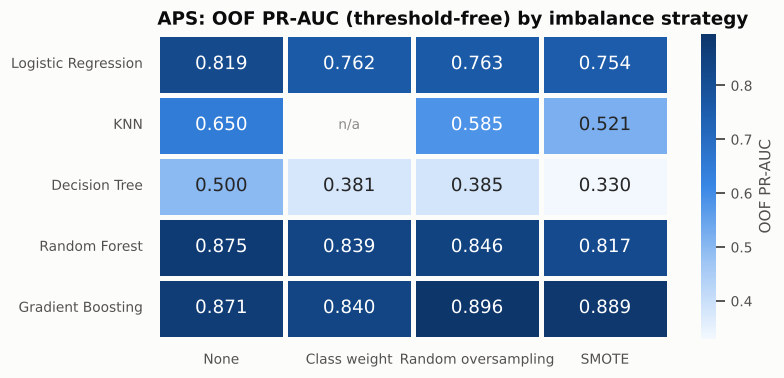

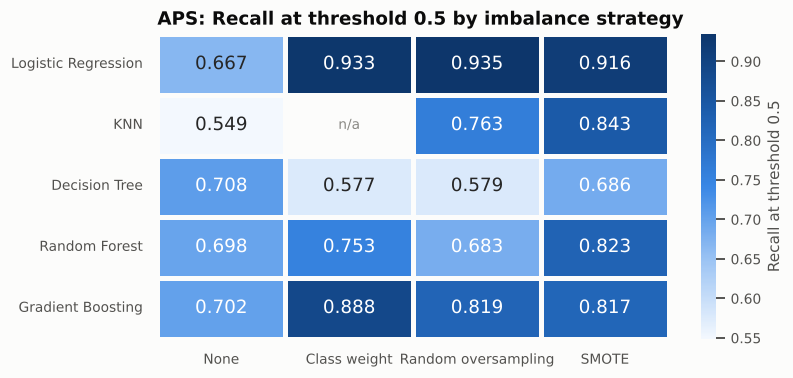

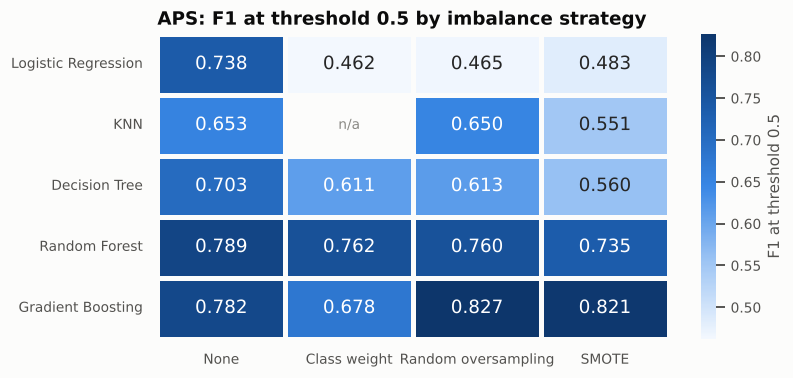

,algo,strategy,oof_pr_auc,cv_precision,cv_recall,cv_f1,cv_fpr,fit_time_s
0,logreg,none,0.819,0.825,0.667,0.738,0.002,2.493
1,logreg,class_weight,0.762,0.307,0.933,0.462,0.036,3.603
2,logreg,ros,0.763,0.310,0.935,0.465,0.035,10.161
3,logreg,smote,0.754,0.328,0.916,0.483,0.032,9.926
4,knn,none,0.650,0.807,0.549,0.653,0.002,1.284
5,knn,ros,0.585,0.566,0.763,0.650,0.010,1.394
6,knn,smote,0.521,0.409,0.843,0.551,0.021,1.553
7,dtree,none,0.500,0.699,0.708,0.703,0.005,17.323
8,dtree,class_weight,0.381,0.650,0.577,0.611,0.005,8.883
9,dtree,ros,0.385,0.653,0.579,0.613,0.005,14.351


In [4]:
for metric, lab, fn in [("oof_pr_auc","OOF PR-AUC (threshold-free)","08"),("cv_recall","Recall at threshold 0.5","09"),("cv_f1","F1 at threshold 0.5","10")]:
    pv = strat.pivot(index="algo", columns="strategy", values=metric).reindex(index=list(ALGO_NAMES), columns=list(STRATEGY_NAMES))
    pv.index = pv.index.map(ALGO_NAMES); pv.columns = pv.columns.map(STRATEGY_NAMES)
    fig = V.strategy_heatmap(pv, f"{DS.upper()}: {lab} by imbalance strategy", cbar_label=lab.split(" (")[0])
    V.save(fig, FIGD / f"{fn}_imbalance_{metric}.png"); plt.show()
display(strat[["algo","strategy","oof_pr_auc","cv_precision","cv_recall","cv_f1","cv_fpr","fit_time_s"]].round(3))

## 4. Hyperparameter tuning (RandomizedSearchCV, scored on average precision)

,algo,strategy,params,search_n_iter,search_folds,search_best_ap,search_time_s,oof_pr_auc,threshold,oof_precision@thr,oof_recall@thr,oof_f1@thr,oof_fp@thr,oof_fn@thr,oof_cost@thr
0,Logistic Regression,none,"{""clf__C"": 4.5705630998014515}",10,5,0.8213,60.3119,0.8207,0.0150,0.2861,0.952,0.4399,2376,48,47760
1,KNN,none,"{""clf__weights"": ""distance"", ""clf__p"": 1, ""clf...",8,3,0.8106,970.2731,0.8175,0.0400,0.3515,0.918,0.5083,1694,82,57940
2,Decision Tree,none,"{""clf__min_samples_leaf"": 20, ""clf__max_depth""...",20,5,0.7267,320.5862,0.7311,0.0030,0.2763,0.916,0.4246,2399,84,65990
3,Random Forest,none,"{""clf__n_estimators"": 200, ""clf__min_samples_l...",8,3,0.8688,670.7665,0.8762,0.0200,0.2699,0.965,0.4218,2611,35,43610
4,Gradient Boosting,ros,"{""clf__l2_regularization"": 6.993395623207715, ...",25,5,0.8991,2763.0159,0.8990,0.0025,0.3429,0.958,0.5050,1836,42,39360


,algo,baseline,tuned (best strategy),gain
0,Logistic Regression,0.8187,0.8207,0.0020
1,KNN,0.6505,0.8175,0.1670
2,Decision Tree,0.4997,0.7311,0.2314
3,Random Forest,0.8750,0.8762,0.0011
4,Gradient Boosting,0.8711,0.8990,0.0280


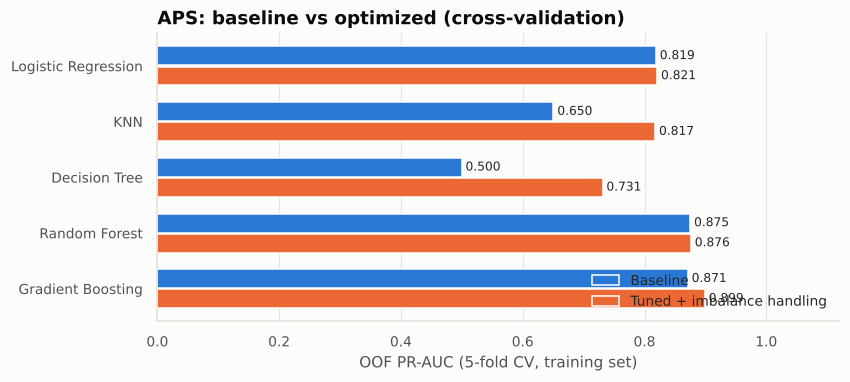

In [5]:
tcols = ["algo","strategy","params","search_n_iter","search_folds","search_best_ap","search_time_s","oof_pr_auc","threshold","oof_precision@thr","oof_recall@thr","oof_f1@thr","oof_fp@thr","oof_fn@thr","oof_cost@thr"]
display(tuned[tcols].assign(algo=lambda d: d.algo.map(ALGO_NAMES)).round(4))
cmp = strat[strat.strategy=="none"][["algo","oof_pr_auc"]].rename(columns={"oof_pr_auc":"baseline"}).merge(
      tuned[["algo","oof_pr_auc"]].rename(columns={"oof_pr_auc":"tuned (best strategy)"}), on="algo")
display(cmp.assign(gain=lambda d: d["tuned (best strategy)"]-d.baseline, algo=lambda d: d.algo.map(ALGO_NAMES)).round(4))
fig, ax = plt.subplots(figsize=(8,3.4)); yy = np.arange(len(cmp))
ax.barh(yy-0.18, cmp.baseline, 0.34, color=V.SERIES[0], label="Baseline"); ax.barh(yy+0.18, cmp["tuned (best strategy)"], 0.34, color=V.SERIES[1], label="Tuned + imbalance handling")
for i,(b,t) in enumerate(zip(cmp.baseline, cmp["tuned (best strategy)"])): ax.text(b, i-0.18, f" {b:.3f}", va="center", fontsize=8); ax.text(t, i+0.18, f" {t:.3f}", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(cmp.algo.map(ALGO_NAMES)); ax.invert_yaxis(); ax.set_xlim(0,1.12); ax.set_xlabel("OOF PR-AUC (5-fold CV, training set)")
ax.set_title("APS: baseline vs optimized (cross-validation)"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
V.save(fig, FIGD / "11_baseline_vs_tuned_cv.png"); plt.show()

## 5. Final evaluation on the held-out test set (scored once)

,model,threshold_rule,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr,fnr,fp,fn,cost
0,logreg_baseline,default_0.5,0.5000,0.9908,0.8721,0.7093,0.7824,0.9906,0.8672,0.0025,0.2907,39,109,54890
1,logreg_tuned,default_0.5,0.5000,0.9906,0.8617,0.7147,0.7813,0.9901,0.8653,0.0028,0.2853,43,107,53930
2,logreg_tuned,oof_cost,0.0150,0.9610,0.3710,0.9547,0.5343,0.9901,0.8653,0.0388,0.0453,607,17,14570
3,knn_baseline,default_0.5,0.5000,0.9878,0.8714,0.5600,0.6818,0.9037,0.7057,0.0020,0.4400,31,165,82810
4,knn_tuned,default_0.5,0.5000,0.9895,0.9442,0.5867,0.7237,0.9681,0.8771,0.0008,0.4133,13,155,77630
5,knn_tuned,oof_cost,0.0400,0.9752,0.4855,0.9387,0.6400,0.9681,0.8771,0.0239,0.0613,373,23,15230
6,dtree_baseline,default_0.5,0.5000,0.9891,0.8073,0.7040,0.7521,0.8500,0.5753,0.0040,0.2960,63,111,56130
7,dtree_tuned,default_0.5,0.5000,0.9892,0.8797,0.6240,0.7301,0.9779,0.8136,0.0020,0.3760,32,141,70820
8,dtree_tuned,oof_cost,0.0030,0.9525,0.3242,0.9467,0.4830,0.9779,0.8136,0.0474,0.0533,740,20,17400
9,rf_baseline,default_0.5,0.5000,0.9927,0.9448,0.7307,0.8241,0.9932,0.9233,0.0010,0.2693,16,101,50660


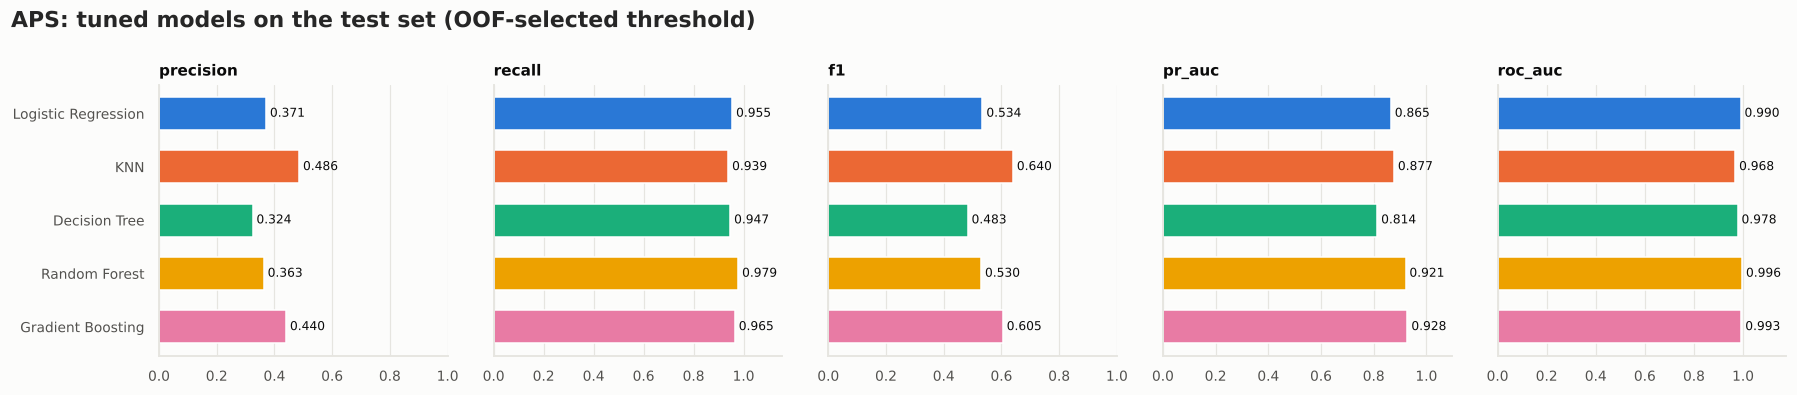

In [6]:
tt = test.copy(); tt["algo"] = tt.model.str.split("_").str[0]
show = ["model","threshold_rule","threshold","accuracy","precision","recall","f1","roc_auc","pr_auc","fpr","fnr","fp","fn"] + (["cost"] if DS == "aps" else [])
display(tt[show].round(4))
final = tt[tt.threshold_rule == "oof_cost"].copy()
fig = V.metric_bars(final, ["precision","recall","f1","pr_auc","roc_auc"], "APS: tuned models on the test set (OOF-selected threshold)")
V.save(fig, FIGD / "12_test_model_comparison.png"); plt.show()

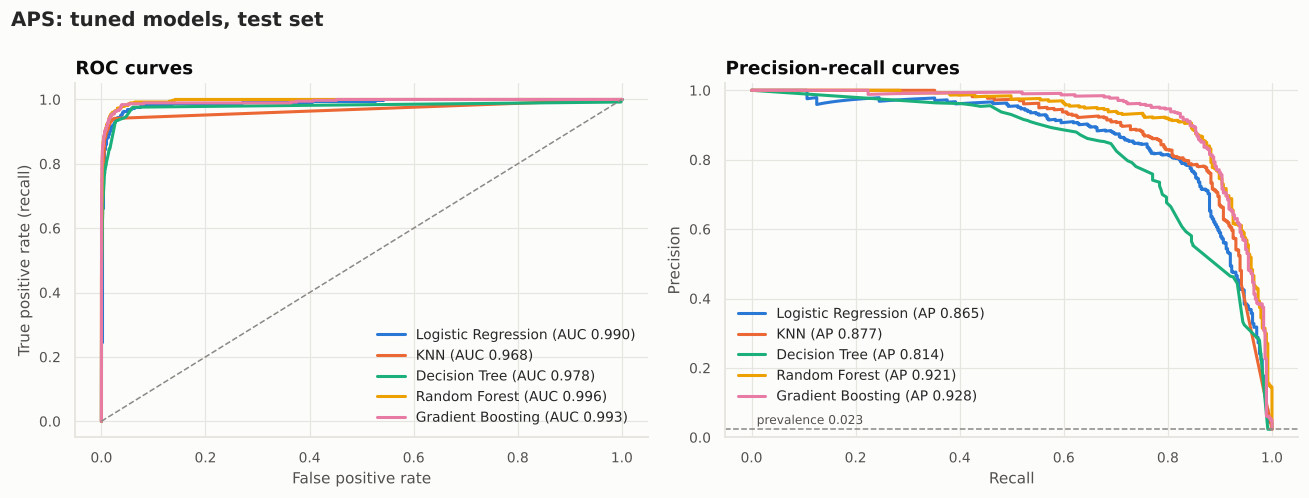

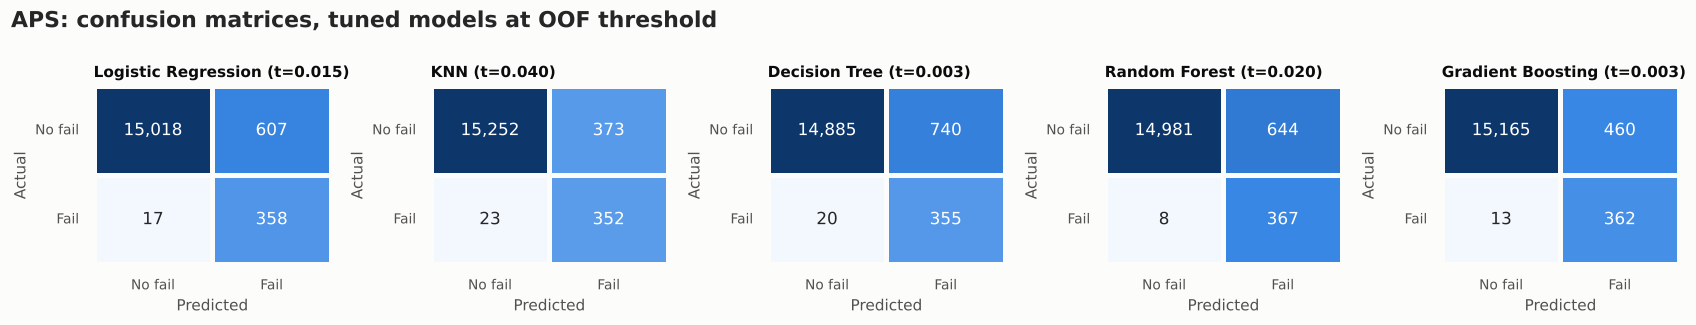

In [7]:
tuned_keys = [f"{a}_tuned" for a in ALGO_NAMES]
V.save(V.roc_pr_curves(y_te, {k: proba[k] for k in tuned_keys}, f"{DS.upper()}: tuned models, test set"), FIGD / "13_roc_pr_curves.png"); plt.show()
thr = {a: float(tuned.set_index("algo").loc[a, "threshold"]) for a in ALGO_NAMES}
preds = {f"{name(a)} (t={thr[a]:.3f})": (proba[f"{a}_tuned"] >= thr[a]).astype(int) for a in ALGO_NAMES}
V.save(V.confusion_grid(y_te, preds, f"{DS.upper()}: confusion matrices, tuned models at OOF threshold"), FIGD / "14_confusion_matrices.png"); plt.show()

## 6. Trade-off: false alarms vs missed failures

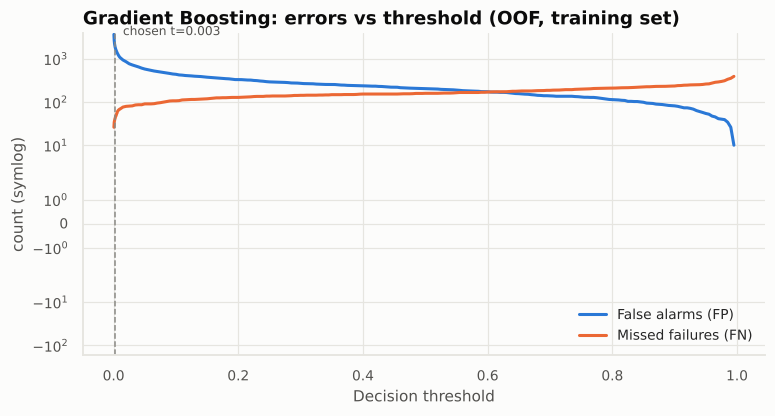

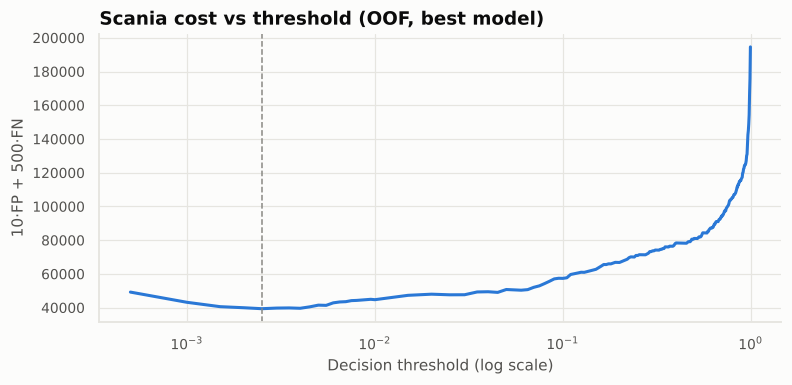

,threshold,precision,recall,f1,fp,fn,cost
4,0.002,0.343,0.958,0.505,1836,42,39360
27,0.050,0.613,0.910,0.733,574,90,50740
37,0.100,0.673,0.894,0.768,434,106,57340
57,0.200,0.728,0.873,0.794,327,127,66770
77,0.300,0.762,0.858,0.807,268,142,73680
117,0.500,0.806,0.842,0.823,203,158,81030
157,0.700,0.855,0.815,0.835,138,185,93880


In [8]:
a = best["algo"]; p_oof = oof_t[a]
from src.preprocessing import ai4i_split, aps_xy
y_tr = (ai4i_split()[2] if DS == "ai4i" else aps_xy()[1]).to_numpy()
rows = [compute_metrics(y_tr, p_oof, t) for t in THRESHOLD_GRID]
tr_df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8,3.8))
ax.plot(tr_df.threshold, tr_df.fp, color=V.SERIES[0], label="False alarms (FP)"); ax.plot(tr_df.threshold, tr_df.fn, color=V.SERIES[1], label="Missed failures (FN)")
ax.axvline(best["threshold"], color=V.MUTED, ls="--", lw=1); ax.text(best["threshold"], ax.get_ylim()[1]*0.92, f"  chosen t={best['threshold']:.3f}", fontsize=8, color=V.INK2)
ax.set_yscale("symlog"); ax.set(xlabel="Decision threshold", ylabel="count (symlog)", title=f"{name(a)}: errors vs threshold (OOF, training set)"); ax.legend()
V.save(fig, FIGD / "15_threshold_tradeoff.png"); plt.show()
if DS == "aps":
    fig, ax = plt.subplots(figsize=(8,3.4)); ax.plot(tr_df.threshold, tr_df.cost, color=V.SERIES[0])
    ax.axvline(best["threshold"], color=V.MUTED, ls="--", lw=1); ax.set_xscale("log"); ax.set(xlabel="Decision threshold (log scale)", ylabel="10·FP + 500·FN", title="Scania cost vs threshold (OOF, best model)")
    V.save(fig, FIGD / "16_cost_vs_threshold.png"); plt.show()
display(tr_df.loc[tr_df.threshold.isin([0.05,0.1,0.2,0.3,0.5,0.7, best['threshold']]), ["threshold","precision","recall","f1","fp","fn"] + (["cost"] if DS == "aps" else [])].round(3))

## 7. Training and inference time

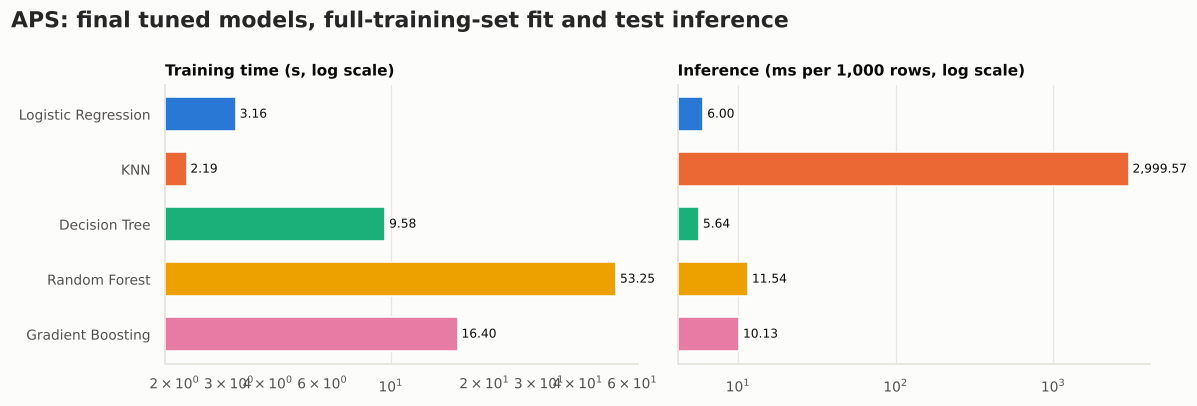

,model,fit_time_s,predict_ms_per_1k
0,logreg_baseline,2.590,7.547
1,logreg_tuned,3.159,6.004
3,knn_baseline,1.992,269.410
4,knn_tuned,2.189,2999.569
6,dtree_baseline,21.557,4.750
7,dtree_tuned,9.578,5.638
9,rf_baseline,36.159,10.463
10,rf_tuned,53.246,11.539
12,gb_baseline,4.561,7.201
13,gb_tuned,16.396,10.129


In [9]:
tm = final[["algo","fit_time_s","predict_ms_per_1k"]]
V.save(V.time_bars(tm, "APS: final tuned models, full-training-set fit and test inference"), FIGD / "17_time_comparison.png"); plt.show()
display(tt.drop_duplicates("model")[["model","fit_time_s","predict_ms_per_1k"]].round(3))

## 8. Explainability

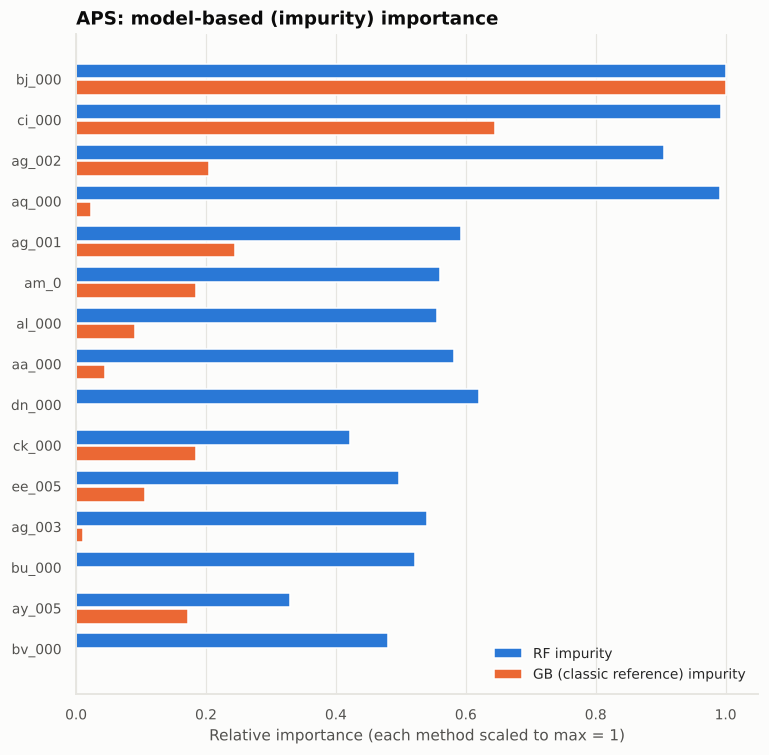

,RF impurity,GB (classic reference) impurity
bj_000,1.000,1.000
ci_000,0.994,0.645
aq_000,0.992,0.023
ag_002,0.905,0.204
dn_000,0.621,0.001
ag_001,0.592,0.244
aa_000,0.582,0.045
am_0,0.561,0.185
al_000,0.556,0.091
ag_003,0.541,0.010


In [10]:
from src.preprocessing import ai4i_split, aps_xy
if DS == "ai4i":
    X_tr, X_te, _, _ = ai4i_split()
else:
    X_tr, _, X_te, _ = aps_xy()
models = {a: joblib.load(C.MODELS_DIR / f"{DS}_{a}_tuned.joblib") for a in ["rf", "gb"]}
imp = {}
rf_imp = E.impurity_importance(models["rf"], X_te); imp["RF impurity"] = rf_imp
gb_imp = E.impurity_importance(models["gb"], X_te)
if gb_imp is None:   # HistGB has no impurity importances -> use the classic GB reference model
    gb_imp = E.impurity_importance(joblib.load(C.MODELS_DIR / f"{DS}_gb_classic_reference.joblib"), X_te); gb_lab = "GB (classic reference) impurity"
else:
    gb_lab = "GB impurity"
imp[gb_lab] = gb_imp
imp_df = pd.DataFrame(imp).fillna(0); imp_df = imp_df / imp_df.max()
V.save(V.importance_bars(imp_df, f"{DS.upper()}: model-based (impurity) importance", top=15), FIGD / "18_impurity_importance.png"); plt.show()
display(imp_df.sort_values("RF impurity", ascending=False).head(12).round(3))

Best: Gradient Boosting


,mean,std
aa_000,0.0302,0.0008
ay_008,0.0079,0.0009
ci_000,0.0069,0.0017
ag_002,0.0062,0.0008
ck_000,0.0057,0.0011
bs_000,0.0040,0.0010
ay_006,0.0031,0.0014
bk_000,0.0030,0.0006
cb_000,0.0024,0.0009
cc_000,0.0023,0.0007


Random Forest


,mean,std
aa_000,0.0286,0.0008
ci_000,0.0258,0.0006
ck_000,0.0137,0.0006
cc_000,0.0100,0.0006
bx_000,0.0091,0.0004
bj_000,0.0089,0.0009
aq_000,0.0087,0.0006
ag_002,0.0081,0.0008
bt_000,0.0078,0.0005
by_000,0.0075,0.0006


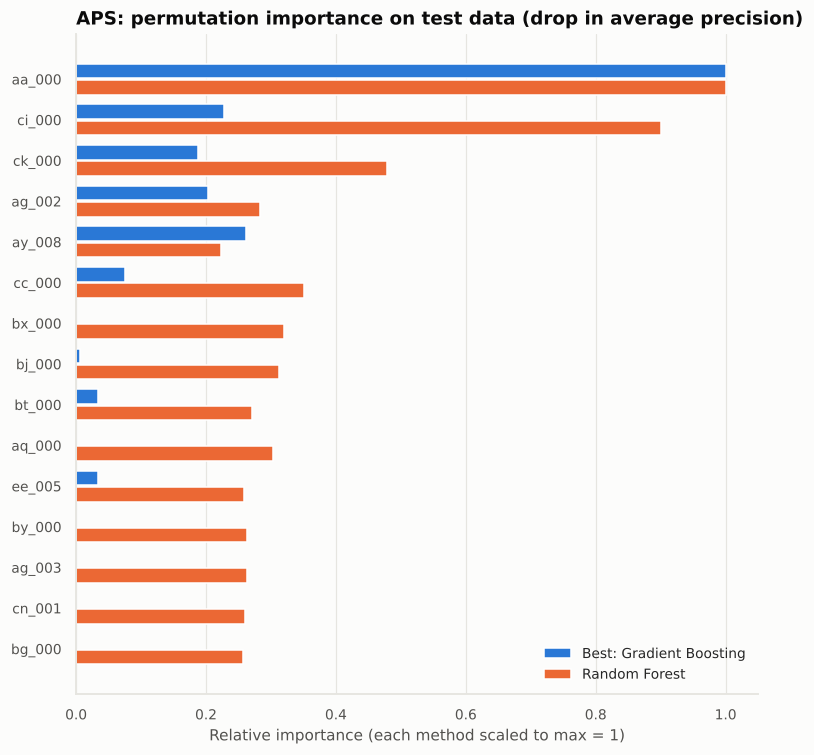

In [11]:
best_pipe = joblib.load(ROOT / best["model_file"])
perm = {}
for lab, pipe in [(f"Best: {name(best['algo'])}", best_pipe), ("Random Forest", models["rf"])]:
    if lab.endswith("Random Forest") and best["algo"] == "rf":
        continue
    perm[lab] = E.permutation(pipe, X_te, y_te, n_repeats=3, max_rows=6000)
perm_df = pd.DataFrame({k: v["mean"] for k, v in perm.items()}).fillna(0)
for k, v in perm.items(): print(k); display(v.head(10).round(4))
V.save(V.importance_bars(perm_df.clip(lower=0) / perm_df.max(), f"{DS.upper()}: permutation importance on test data (drop in average precision)", top=15), FIGD / "19_permutation_importance.png"); plt.show()
pd.concat({**{"impurity_"+k: v for k, v in imp.items()}, **{"perm_"+k: v["mean"] for k, v in perm.items()}}, axis=1).to_csv(R / f"{DS}_feature_importance.csv")

SHAP model: Gradient Boosting | sample: 1500


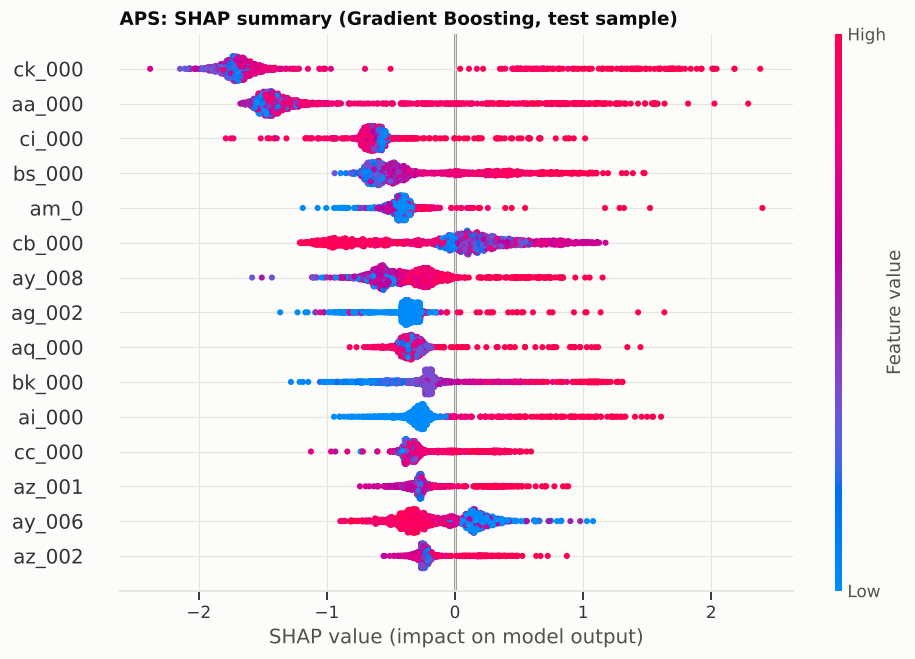

,mean |SHAP|
ck_000,1.6376
aa_000,1.2708
ci_000,0.6351
bs_000,0.5018
am_0,0.4283
cb_000,0.4190
ay_008,0.4190
ag_002,0.3787
aq_000,0.3573
bk_000,0.3469


In [12]:
import shap
shap_algo = best["algo"] if best["algo"] in ("rf","gb","dtree") else "gb"
shap_pipe = joblib.load(C.MODELS_DIR / f"{DS}_{shap_algo}_tuned.joblib")
sample = X_te.sample(min(len(X_te), 1500), random_state=C.RANDOM_STATE)
sv, Xt = E.shap_values(shap_pipe, sample)
print("SHAP model:", name(shap_algo), "| sample:", len(sample))
plt.figure(); shap.summary_plot(sv, Xt, max_display=15, show=False, plot_size=(9, 6))
plt.title(f"{DS.upper()}: SHAP summary ({name(shap_algo)}, test sample)", loc="left", fontsize=12, fontweight="bold")
V.save(plt.gcf(), FIGD / "20_shap_summary.png"); plt.show()
ms = pd.Series(np.abs(sv).mean(0), index=Xt.columns).sort_values(ascending=False)
ms.to_csv(R / f"{DS}_shap_mean_abs.csv", header=["mean_abs_shap"]); display(ms.head(12).round(4).to_frame("mean |SHAP|"))

## 9. Selected model

In [13]:
print(json.dumps(best, indent=2))
display(tt[(tt.model == f"{best['algo']}_tuned")][show].round(4))

{
  "dataset": "aps",
  "algo": "gb",
  "strategy": "ros",
  "params": {
    "clf__l2_regularization": 6.993395623207715,
    "clf__learning_rate": 0.19691503323109746,
    "clf__max_iter": 200,
    "clf__max_leaf_nodes": 31,
    "clf__min_samples_leaf": 50
  },
  "threshold": 0.0025,
  "model_file": "models/aps_gb_tuned.joblib",
  "criterion": "lowest OOF Scania cost at the OOF-selected threshold (tie-break: OOF PR-AUC)"
}


,model,threshold_rule,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr,fnr,fp,fn,cost
13,gb_tuned,default_0.5,0.5000,0.9938,0.8747,0.8560,0.8652,0.9933,0.9282,0.0029,0.1440,46,54,27460
14,gb_tuned,oof_cost,0.0025,0.9704,0.4404,0.9653,0.6048,0.9933,0.9282,0.0294,0.0347,460,13,11100


## 10. Findings

**Preprocessing.** Mean, median, median + flags, dropping >70%-missing columns, adding
histogram totals and HistGB's native NaN handling all landed within ~0.01 OOF PR-AUC of each
other (HistGB 0.879–0.888; LR 0.762–0.766), inside the fold-to-fold spread. Median imputation
+ sentinel flag + missing count was kept: robust to the heavy skew, it keeps the documented
`ac_000` sentinel, and it gives every algorithm the same complete input (SMOTE requires one).
The engineered `n_missing` feature ranks 46th of 171 by mean |SHAP|; the sentinel flag ranks 69th.

**Model ranking (CV).** Tuned OOF PR-AUC: Gradient Boosting (HistGB) 0.899 > Random Forest
0.876 > Logistic Regression 0.821 ≈ KNN 0.817 > Decision Tree 0.731. Logistic Regression is
much stronger here than on AI4I. After log-scaling, many counters separate the classes almost
monotonically (34 features have a single-feature |AUC − 0.5| above 0.4; see notebook 03).

**Imbalance handling.** Only Gradient Boosting benefited: random oversampling raised its OOF
PR-AUC from 0.871 to 0.896 (SMOTE 0.889). For LR, KNN, DT and RF, every strategy lowered
PR-AUC, and for DT and RF it also lowered F1 at 0.5. As with AI4I, most of the useful
"imbalance handling" comes from moving the decision threshold.

**Cost-based thresholds are the single biggest lever.** At the default 0.5 threshold, the
tuned GB costs 27,460 on the test set (54 missed failures). At the OOF-selected threshold
of 0.0025, it costs **11,100** (13 missed, 460 false alarms). A missed failure costs 50× a
false alarm, so the cost-optimal model flags about 5% of test trucks (822 of 16,000) to catch 96.5% of APS failures.

**Test results (scored once).** Selected model, chosen on OOF cost: Gradient Boosting with
random oversampling. Test cost 11,100; recall 0.965; precision 0.440; PR-AUC 0.928; ROC-AUC 0.993.
Tuned Random Forest scored a lower test cost (10,440: 8 missed, 644 false alarms), but it
was not selected because its OOF cost was higher (43,610 vs 39,360). Picking it after seeing
test results would be test-set selection. For reference, the official IDA 2016 challenge
results on this test set were 9,920 / 10,900 / 11,480 for the top three entries.

**Explainability.** SHAP, permutation and impurity importance agree on a small core set:
`aa_000`, `ck_000`, `ci_000`, `ag_002` (a histogram bin), `bs_000`, `aq_000` and `bj_000`.
The features are anonymized, so these can't be mapped to physical components, and they
are statistical associations, not causes.

**Cost of the model zoo.** Classic `GradientBoostingClassifier` (untuned) took 187 s to fit
vs 16 s for the tuned HistGB, and scored a lower test PR-AUC (0.870 vs 0.928). Tuned KNN
(distance-weighted, Manhattan) needs ~3 s per 1,000 predictions. That is impractical at
fleet scale, though its accuracy is reasonable.

**Caveats.** The negative class is trucks with *other* failures, not healthy trucks. The test
set has a higher positive rate (2.34%) than training (1.67%). OOF costs cover 60,000 rows and
test costs 16,000, so the two are not directly comparable. Search budgets were reduced for
RF and KNN on this 2-core machine (see the technical report).